In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
df=pd.read_excel(r"C:\Users\LENOVO\OneDrive\ドキュメント\ml\.venv\AlSi10Mg PSP feature table.xlsx")
print("Dataset Shape: ",df.shape)
display(df.iloc[:10,:8])
display(df.iloc[-10:,:8])


Dataset Shape:  (63, 46)


,Processing Data,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,Parameter Set,NaN,Processing Parameters,NaN,NaN,NaN,P-V process features,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,Power P (W),Speed v (mm/s),Layer Thickness t (mm),Hatch Spacing h (mm),LED (J/mm),VED (J/mm3)
3,1,Small hatch spacing group (set 1 to 32),60,250,0.06,0.1,0.24,40
4,2,NaN,160,250,0.06,0.1,0.64,106.666667
5,3,NaN,160,800,0.06,0.1,0.2,33.333333
6,4,NaN,160,1350,0.06,0.1,0.118519,19.753086
7,5,NaN,260,250,0.06,0.1,1.04,173.333333
8,6,NaN,260,800,0.06,0.1,0.325,54.166667
9,7,NaN,260,1350,0.06,0.1,0.192593,32.098765


,Processing Data,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
53,51,NaN,260,500,0.06,0.15,0.52,57.777778
54,52,NaN,360,500,0.06,0.15,0.72,80
55,53,NaN,460,500,0.06,0.15,0.92,102.222222
56,54,NaN,210,250,0.06,0.15,0.84,93.333333
57,55,NaN,210,500,0.06,0.15,0.42,46.666667
58,56,NaN,210,800,0.06,0.15,0.2625,29.166667
59,57,NaN,210,1100,0.06,0.15,0.190909,21.212121
60,58,NaN,260,1100,0.06,0.15,0.236364,26.262626
61,59,NaN,360,1100,0.06,0.15,0.327273,36.363636
62,60,NaN,460,1100,0.06,0.15,0.418182,46.464646


In [6]:
# Extract experimental rows and the required columns
data = df.iloc[4:, [2, 3, 4, 5, 32]].copy()

# Assign meaningful column names
data.columns = [
    "laser_power_W",
    "scan_speed_mm_s",
    "layer_thickness_mm",
    "hatch_spacing_mm",
    "xct_porosity"
]

# Convert the selected columns to numerical values
data = data.apply(pd.to_numeric, errors="coerce")

# Display the cleaned table
display(data.head(10))

# Check the dimensions
print("Cleaned dataset shape:", data.shape)

,laser_power_W,scan_speed_mm_s,layer_thickness_mm,hatch_spacing_mm,xct_porosity
4,160,250,0.06,0.1,0.270462
5,160,800,0.06,0.1,0.260757
6,160,1350,0.06,0.1,0.069400
7,260,250,0.06,0.1,0.091498
8,260,800,0.06,0.1,0.113332
9,260,1350,0.06,0.1,0.246629
10,260,1900,0.06,0.1,0.098483
11,360,250,0.06,0.1,0.271678
12,360,800,0.06,0.1,0.216508
13,360,1350,0.06,0.1,0.248080


Cleaned dataset shape: (59, 5)


In [7]:
# Check the dimensions
print("Shape:", data.shape)

# Check column data types
print("\nData types:")
print(data.dtypes)

# Count missing values
print("\nMissing values:")
print(data.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", data.duplicated().sum())

# Generate descriptive statistics
print("\nDescriptive statistics:")
display(data.describe().round(4))



Shape: (59, 5)

Data types:
laser_power_W           int64
scan_speed_mm_s         int64
layer_thickness_mm    float64
hatch_spacing_mm      float64
xct_porosity          float64
dtype: object

Missing values:
laser_power_W         0
scan_speed_mm_s       0
layer_thickness_mm    0
hatch_spacing_mm      0
xct_porosity          0
dtype: int64

Duplicate rows: 0

Descriptive statistics:


,laser_power_W,scan_speed_mm_s,layer_thickness_mm,hatch_spacing_mm,xct_porosity
count,59.0000,59.0000,59.00,59.0000,59.0000
mean,291.3559,959.3220,0.06,0.1237,1.9807
std,125.5671,722.5717,0.00,0.0252,3.0836
min,60.0000,250.0000,0.06,0.1000,0.0694
25%,210.0000,500.0000,0.06,0.1000,0.2055
50%,260.0000,800.0000,0.06,0.1000,0.2935
75%,360.0000,1350.0000,0.06,0.1500,2.5140
max,460.0000,3000.0000,0.06,0.1500,14.4274


In [8]:
# Save the cleaned dataset
data.to_csv("lpbf_porosity_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


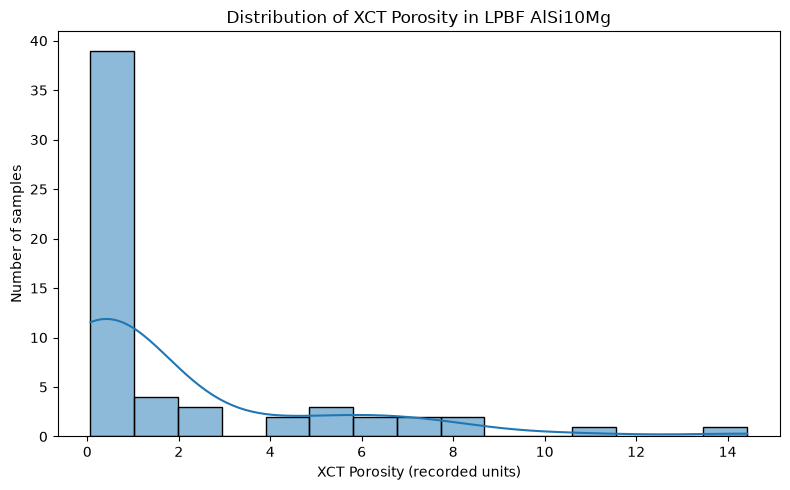

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="xct_porosity",
    bins=15,
    kde=True
)

plt.title("Distribution of XCT Porosity in LPBF AlSi10Mg")
plt.xlabel("XCT Porosity (recorded units)")
plt.ylabel("Number of samples")

plt.tight_layout()
plt.show()

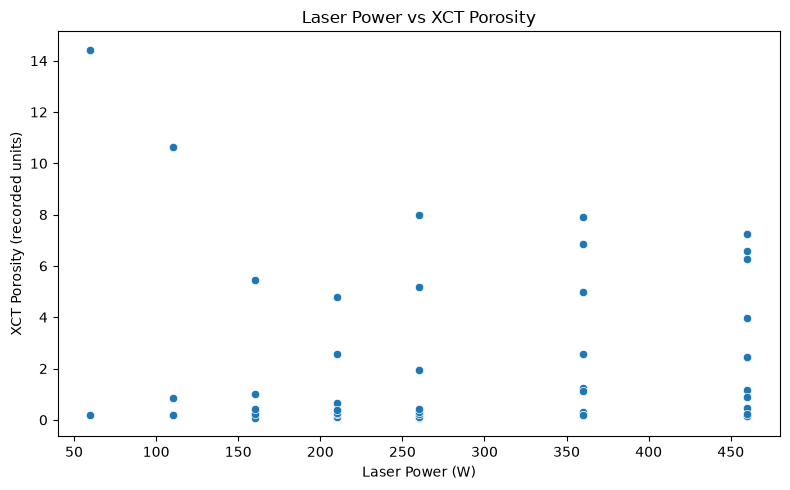

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="laser_power_W",
    y="xct_porosity"
)

plt.title("Laser Power vs XCT Porosity")
plt.xlabel("Laser Power (W)")
plt.ylabel("XCT Porosity (recorded units)")

plt.tight_layout()
plt.show()

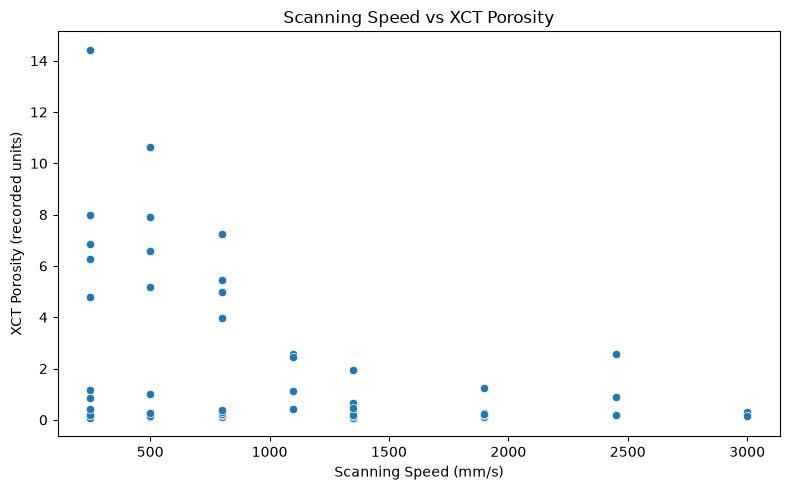

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="scan_speed_mm_s",
    y="xct_porosity"
)

plt.title("Scanning Speed vs XCT Porosity")
plt.xlabel("Scanning Speed (mm/s)")
plt.ylabel("XCT Porosity (recorded units)")

plt.tight_layout()
plt.show()


In [12]:
# Calculate correlations between numerical variables
correlation_matrix = data.corr(numeric_only=True)

# Display the correlation matrix
display(correlation_matrix.round(3))


,laser_power_W,scan_speed_mm_s,layer_thickness_mm,hatch_spacing_mm,xct_porosity
laser_power_W,1.000,0.445,NaN,0.033,-0.043
scan_speed_mm_s,0.445,1.000,NaN,-0.162,-0.302
layer_thickness_mm,NaN,NaN,NaN,NaN,NaN
hatch_spacing_mm,0.033,-0.162,NaN,1.000,0.529
xct_porosity,-0.043,-0.302,NaN,0.529,1.000


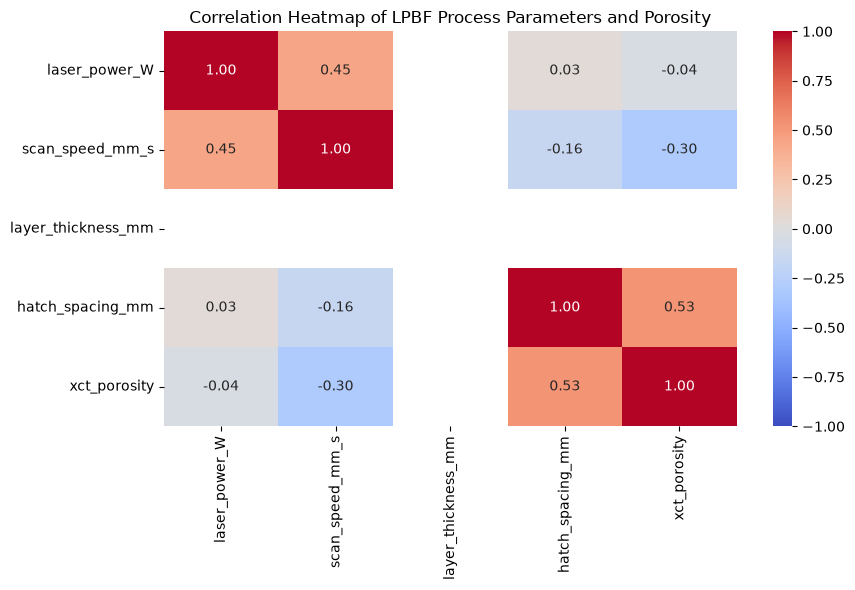

In [13]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of LPBF Process Parameters and Porosity")
plt.tight_layout()
plt.show()

In [14]:
# Calculate volumetric energy density
data["VED_J_mm3"] = (
    data["laser_power_W"]
    / (
        data["scan_speed_mm_s"]
        * data["hatch_spacing_mm"]
        * data["layer_thickness_mm"]
    )
)

# Display the calculated values
display(
    data[
        [
            "laser_power_W",
            "scan_speed_mm_s",
            "hatch_spacing_mm",
            "layer_thickness_mm",
            "VED_J_mm3",
            "xct_porosity"
        ]
    ].head(10)
)

,laser_power_W,scan_speed_mm_s,hatch_spacing_mm,layer_thickness_mm,VED_J_mm3,xct_porosity
4,160,250,0.1,0.06,106.666667,0.270462
5,160,800,0.1,0.06,33.333333,0.260757
6,160,1350,0.1,0.06,19.753086,0.069400
7,260,250,0.1,0.06,173.333333,0.091498
8,260,800,0.1,0.06,54.166667,0.113332
9,260,1350,0.1,0.06,32.098765,0.246629
10,260,1900,0.1,0.06,22.807018,0.098483
11,360,250,0.1,0.06,240.000000,0.271678
12,360,800,0.1,0.06,75.000000,0.216508
13,360,1350,0.1,0.06,44.444444,0.248080


In [15]:
# Define input features
X = data[
    [
        "laser_power_W",
        "scan_speed_mm_s",
        "hatch_spacing_mm"
    ]
]

# Define target variable
y = data["xct_porosity"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Input features shape: (59, 3)
Target shape: (59,)


,laser_power_W,scan_speed_mm_s,hatch_spacing_mm
4,160,250,0.1
5,160,800,0.1
6,160,1350,0.1
7,260,250,0.1
8,260,800,0.1


4    0.270462
5    0.260757
6    0.069400
7    0.091498
8    0.113332
Name: xct_porosity, dtype: float64

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 47
Testing samples: 12


In [17]:
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict porosity for the test set
y_pred_lr = lr_model.predict(X_test)

print("Predictions:", y_pred_lr)
print("Actual values:", y_test.to_numpy())

Predictions: [ 1.07942197  0.07068106  4.06602707  2.06581602  2.04854524  3.59764194
  3.36127227  1.10423387  3.26884392 -1.60682932  3.76204095  1.40821999]
Actual values: [ 0.27046168  0.24662905  8.0004916   1.14715372  0.87219975  0.27704675
  1.1160243   0.24439436 10.62926356  0.29348702  5.19657566  0.09149784]


In [18]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Calculate MAE
mae_lr = mean_absolute_error(y_test, y_pred_lr)

# Calculate RMSE
rmse_lr = mean_squared_error(
    y_test,
    y_pred_lr
) ** 0.5

# Calculate R-squared
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", round(mae_lr, 4))
print("RMSE:", round(rmse_lr, 4))
print("R2  :", round(r2_lr, 4))

Linear Regression Results
-------------------------
MAE : 2.121
RMSE: 2.8399
R2  : 0.3114


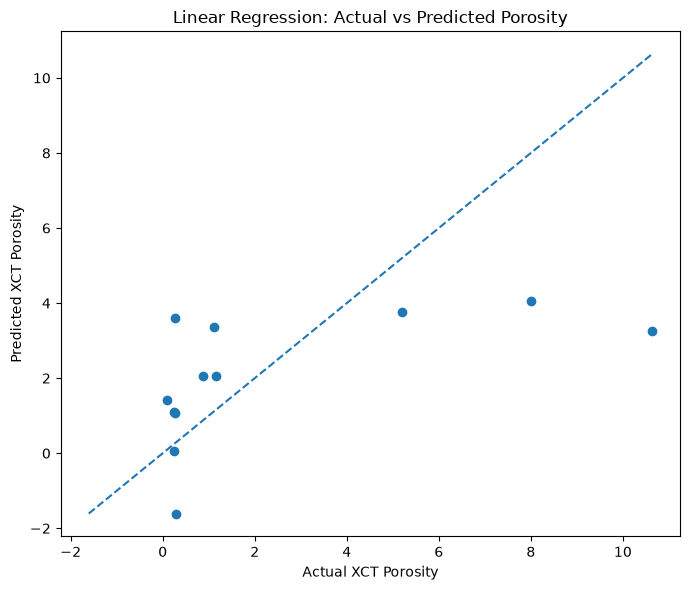

In [19]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_lr
)

# Perfect-prediction reference line
lower = min(y_test.min(), y_pred_lr.min())
upper = max(y_test.max(), y_pred_lr.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual XCT Porosity")
plt.ylabel("Predicted XCT Porosity")
plt.title("Linear Regression: Actual vs Predicted Porosity")

plt.tight_layout()
plt.show()


In [20]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=2,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict porosity for the test data
y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions:")
print(y_pred_rf)

Random Forest predictions:
[0.42784921 0.28753687 3.76379215 1.30754503 1.04997616 2.96059967
 1.77437729 0.19603682 3.7096434  0.79820417 2.87295372 0.40603222]


In [21]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = mean_squared_error(
    y_test,
    y_pred_rf
) ** 0.5

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("----------------------")
print("MAE :", round(mae_rf, 4))
print("RMSE:", round(rmse_rf, 4))
print("R2  :", round(r2_rf, 4))

Random Forest Results
----------------------
MAE : 1.5188
RMSE: 2.5707
R2  : 0.4357


In [22]:
from sklearn.ensemble import GradientBoostingRegressor

# Create the Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.03,
    max_depth=2,
    loss="huber",
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

# Generate predictions
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting predictions:")
print(y_pred_gb)

Gradient Boosting predictions:
[-0.04498137  0.20120988  2.66519012  1.36335323  1.5265777   2.66519012
  2.33934424  0.01369779  2.60651096  0.65845486  2.66519012  0.01369779]


In [23]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)

rmse_gb = mean_squared_error(
    y_test,
    y_pred_gb
) ** 0.5

r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE :", round(mae_gb, 4))
print("RMSE:", round(rmse_gb, 4))
print("R2  :", round(r2_gb, 4))

Gradient Boosting Results
-------------------------
MAE : 1.7838
RMSE: 2.989
R2  : 0.2372


In [24]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_lr,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse_lr,
        rmse_rf,
        rmse_gb
    ],
    "R2": [
        r2_lr,
        r2_rf,
        r2_gb
    ]
})

display(results.round(4))

,Model,MAE,RMSE,R2
0,Linear Regression,2.1210,2.8399,0.3114
1,Random Forest,1.5188,2.5707,0.4357
2,Gradient Boosting,1.7838,2.9890,0.2372


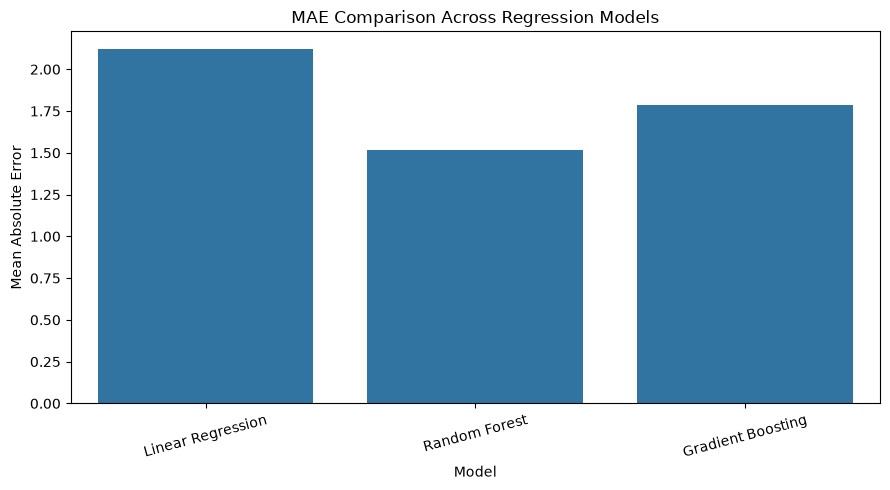

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x="Model",
    y="MAE"
)

plt.title("MAE Comparison Across Regression Models")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [28]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

# Define five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=2,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=2,
        loss="huber",
        random_state=42
    )
}

# Store the results
cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    # Convert negative MAE scores to positive values
    mae_scores = -scores

    cv_results.append({
        "Model": name,
        "Mean CV MAE": mae_scores.mean(),
        "Std CV MAE": mae_scores.std()
    })

# Display the results
cv_results = pd.DataFrame(cv_results)

display(cv_results.round(4))

,Model,Mean CV MAE,Std CV MAE
0,Linear Regression,1.8880,0.5089
1,Random Forest,1.6732,0.5382
2,Gradient Boosting,2.0417,0.5773


In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold

# Define the base model
rf = RandomForestRegressor(
    random_state=42
)

# Define the hyperparameter combinations
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3, 4, None],
    "min_samples_split": [2, 4],
    "min_samples_leaf": [1, 2, 3]
}

# Define cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create the grid search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Train and evaluate all parameter combinations
grid_search.fit(X_train, y_train)

print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation MAE:")
print(-grid_search.best_score_)

Best hyperparameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best cross-validation MAE:
1.6374057341423627


In [30]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Retrieve the tuned model
best_rf = grid_search.best_estimator_

# Predict on the untouched test set
y_pred_tuned = best_rf.predict(X_test)

# Calculate evaluation metrics
mae_tuned = mean_absolute_error(
    y_test,
    y_pred_tuned
)

rmse_tuned = mean_squared_error(
    y_test,
    y_pred_tuned
) ** 0.5

r2_tuned = r2_score(
    y_test,
    y_pred_tuned
)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE :", round(mae_tuned, 4))
print("RMSE:", round(rmse_tuned, 4))
print("R2  :", round(r2_tuned, 4))

Tuned Random Forest Results
---------------------------
MAE : 1.7692
RMSE: 3.0774
R2  : 0.1914


In [31]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate permutation importance on the test set
importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=50,
    random_state=42
)

# Create a DataFrame containing the results
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.round(4))

,Feature,Importance,Std
2,hatch_spacing_mm,0.9636,0.3850
1,scan_speed_mm_s,0.7986,0.3332
0,laser_power_W,-0.0378,0.1967


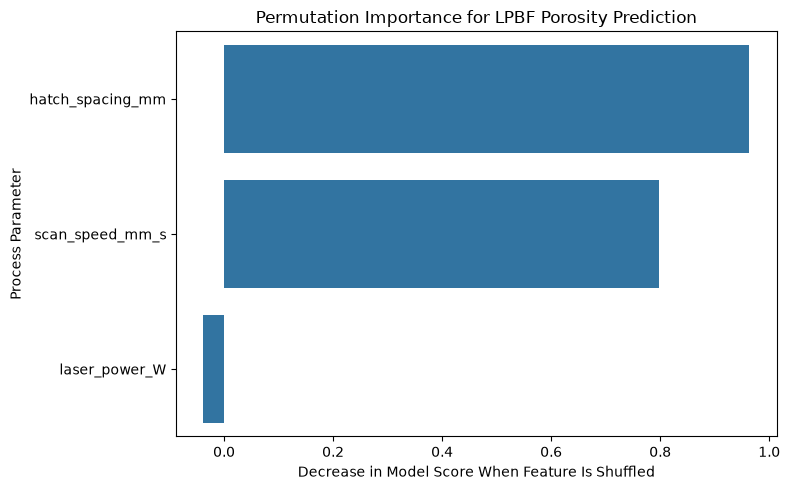

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Importance for LPBF Porosity Prediction")
plt.xlabel("Decrease in Model Score When Feature Is Shuffled")
plt.ylabel("Process Parameter")

plt.tight_layout()
plt.show()

In [33]:
from sklearn.metrics import mean_absolute_error

# Predictions on training data
y_train_pred_original = rf_model.predict(X_train)
y_train_pred_tuned = best_rf.predict(X_train)

# Calculate training MAE
train_mae_original = mean_absolute_error(
    y_train,
    y_train_pred_original
)

train_mae_tuned = mean_absolute_error(
    y_train,
    y_train_pred_tuned
)

# Compare training and test errors
comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Training MAE": [
        train_mae_original,
        train_mae_tuned
    ],
    "Test MAE": [
        mae_rf,
        mae_tuned
    ]
})

display(comparison.round(4))

,Model,Training MAE,Test MAE
0,Original Random Forest,1.0235,1.5188
1,Tuned Random Forest,0.5886,1.7692


In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate, KFold
import pandas as pd

# Define five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define simpler Random Forest configurations
rf_candidates = {
    "Original RF": RandomForestRegressor(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=2,
        random_state=42
    ),

    "Shallow RF": RandomForestRegressor(
        n_estimators=200,
        max_depth=2,
        min_samples_leaf=3,
        random_state=42
    ),

    "Moderate RF": RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=3,
        random_state=42
    ),

    "Regularised RF": RandomForestRegressor(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=4,
        min_samples_split=6,
        random_state=42
    )
}

# Store cross-validation results
candidate_results = []

for name, model in rf_candidates.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        return_train_score=True
    )

    train_mae = -scores["train_score"]
    validation_mae = -scores["test_score"]

    candidate_results.append({
        "Model": name,
        "Mean Training MAE": train_mae.mean(),
        "Mean CV MAE": validation_mae.mean(),
        "CV MAE Std": validation_mae.std()
    })

candidate_results = pd.DataFrame(candidate_results)

display(
    candidate_results.sort_values(
        by="Mean CV MAE"
    ).round(4)
)

,Model,Mean Training MAE,Mean CV MAE,CV MAE Std
0,Original RF,1.0528,1.6732,0.5382
2,Moderate RF,1.2080,1.7264,0.5431
3,Regularised RF,1.3240,1.7671,0.5343
1,Shallow RF,1.3476,1.7964,0.5447


In [35]:
import pandas as pd
import numpy as np

# Generate predictions using the original Random Forest
y_pred_rf = rf_model.predict(X_test)

# Create a table containing actual and predicted values
prediction_analysis = X_test.copy()

prediction_analysis["Actual_Porosity"] = y_test
prediction_analysis["Predicted_Porosity"] = y_pred_rf

# Calculate prediction errors
prediction_analysis["Error"] = (
    prediction_analysis["Actual_Porosity"]
    - prediction_analysis["Predicted_Porosity"]
)

# Calculate absolute errors
prediction_analysis["Absolute_Error"] = (
    prediction_analysis["Error"].abs()
)

# Sort observations by absolute error
prediction_analysis = prediction_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
)

display(prediction_analysis.round(4))

,laser_power_W,scan_speed_mm_s,hatch_spacing_mm,Actual_Porosity,Predicted_Porosity,Error,Absolute_Error
51,110,500,0.15,10.6293,3.7096,6.9196,6.9196
38,260,250,0.15,8.0005,3.7638,4.2367,4.2367
57,210,500,0.15,0.2770,2.9606,-2.6836,2.6836
53,260,500,0.15,5.1966,2.8730,2.3236,2.3236
61,360,1100,0.15,1.1160,1.7744,-0.6584,0.6584
16,360,3000,0.10,0.2935,0.7982,-0.5047,0.5047
7,260,250,0.10,0.0915,0.4060,-0.3145,0.3145
49,460,2450,0.15,0.8722,1.0500,-0.1778,0.1778
17,460,250,0.10,1.1472,1.3075,-0.1604,0.1604
4,160,250,0.10,0.2705,0.4278,-0.1574,0.1574


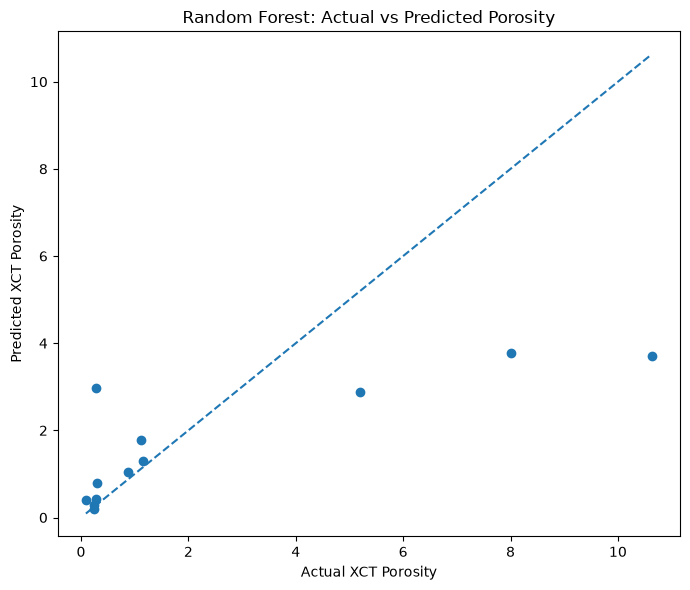

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_rf
)

lower = min(y_test.min(), y_pred_rf.min())
upper = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual XCT Porosity")
plt.ylabel("Predicted XCT Porosity")

plt.title("Random Forest: Actual vs Predicted Porosity")

plt.tight_layout()
plt.show()

In [37]:
import pandas as pd
import numpy as np

# Copy the existing prediction analysis
error_analysis = prediction_analysis.copy()

# Divide observations into porosity groups
error_analysis["Porosity_Group"] = pd.cut(
    error_analysis["Actual_Porosity"],
    bins=[-np.inf, 1, 5, np.inf],
    labels=["Low", "Medium", "High"]
)

# Calculate error statistics for each group
group_results = error_analysis.groupby(
    "Porosity_Group",
    observed=False
).agg(
    Number_of_Samples=("Absolute_Error", "count"),
    Mean_Absolute_Error=("Absolute_Error", "mean"),
    Maximum_Absolute_Error=("Absolute_Error", "max")
)

display(group_results.round(4))

,Number_of_Samples,Mean_Absolute_Error,Maximum_Absolute_Error
Porosity_Group,,,
Low,7,0.5610,2.6836
Medium,2,0.4094,0.6584
High,3,4.4933,6.9196


In [38]:
import joblib

# Save the trained Random Forest model
joblib.dump(
    rf_model,
    "lpbf_porosity_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
